# Assignment 4

In [1]:
# Import the necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import time
import ipywidgets as widgets
from IPython.display import display

In [2]:
BOOK_PATH = "goblet_book.txt"

## Data Handler Class

In [3]:
class DataHandler:
    """
    Class for data management.

    Args:
        file_name: The name of the file to read.
    Attributes:
        data: The data read from the file.
        data_vector: A list of unique characters in the data.
        K: Dim. of the data (length of data_vector).
    """

    def __init__(self, file_name):

        # Load data:
        try:
            with open(file_name, "r", encoding="utf-8") as fid:
                self.data = fid.read()
        except FileNotFoundError:
            raise FileNotFoundError(f"Could not find file: {file_name}")
        
        # Store characters, length and dimension
        self.data_vector = sorted(list(set(self.data)))
        self.K = len(self.data_vector)
        self.N = len(self.data)

        # Create fast lookup dictionaries
        self.char_to_ind_dict = {char: ind for ind, char in enumerate(self.data_vector)}
        self.ind_to_char_dict = {ind: char for ind, char in enumerate(self.data_vector)}

        # Prepare a rng (which will likely be updated by network later)
        self.rng = np.random.default_rng()
        
        # Print status
        print(f"DataHandler: Loaded file {file_name} with dimension {self.K} of length {self.N}.")

    def char_to_ind(self, char):
        """
        Convert a character to an index based on the dict. char_to_ind_dict.

        Args:
            char: The character to convert.
        Returns:
            The index of the character in the data vector.
        """
        return self.char_to_ind_dict[char]
    
    def sec_to_one_hot(self, sec):
        seq_len = len(sec)
        one_hot = np.zeros((self.K, seq_len))
        indices = [self.char_to_ind_dict[c] for c in sec]
        one_hot[indices, np.arange(seq_len)] = 1
        return one_hot

    def ind_to_char(self, ind):
        """
        Convert an index to a character based on the dict. ind_to_char_dict.

        Args:
            ind: The index to convert.
        Returns:
            The character corresponding to the index in the data vector.
        """
        return self.ind_to_char_dict[ind]
    
    def get_input_seq(self, e, seq_length):
        return self.data[e:e+seq_length]
    
    def get_target_seq(self, e, seq_length):
        return self.data[e+1 : e+seq_length+1]
    
    def get_target_indices(self, e, seq_length):
        raw_str = self.get_target_seq(e, seq_length)
        return np.array([self.char_to_ind_dict[c] for c in raw_str])
    
    # Note that the following two functions should be possible
    # to combine and make shorter...
    def get_input_seq_one_hot(self, e, seq_length):
        return self.sec_to_one_hot(self.get_input_seq(e, seq_length))
    
    def get_target_seq_one_hot(self, e, seq_length):
        return self.sec_to_one_hot(self.get_target_seq(e, seq_length))

    def get_random_char_one_hot(self):
        random_char = self.rng.choice(self.data_vector)
        return self.sec_to_one_hot(random_char)

We explore the data a bit before continuing...

In [4]:
data_handler = DataHandler(BOOK_PATH)
# print(f"data_vector: {data_handler.data_vector}")
# print(f"char_to_ind_dict: {data_handler.char_to_ind_dict}")
# print(f"ind_to_char_dict: {data_handler.ind_to_char_dict}")

DataHandler: Loaded file goblet_book.txt with dimension 80 of length 1107542.


## Neural Network Class

In [5]:
class Activation:
    @staticmethod
    def softmax(X):
        """
        Softmax activation function.

        Args:
            X: Input array of shape (K, N)
        Returns:
            Output array of shape (K, N)
        """
        exp_Z = np.exp(X - np.max(X, axis=0, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)
    @staticmethod
    def softmax_derivative(**kwargs):
        """
        Args:
            X: Input array (pre-activation scores)
            Y: One-hot-encoded labels
        Returns:
            P - Y (the proper gradient for cross-entropy + softmax)
        """
        X = kwargs['X']
        Y = kwargs['Y']
        P = Activation.softmax(X)
        return P - Y  # Return P - Y_labels directly
    
    @staticmethod
    def tahn(X):
        """
        Tanh activation function.

        Args:
            X: Input array of shape (d, N)
        Returns:
            Output array of shape (d, N)
        """
        return np.tanh(X)
    @staticmethod
    def tahn_derivative(**kwargs):
        """
        Tanh derivative function.

        Source: https://medium.com/@vikrampande783/derivative-of-sigmoid-and-tanh-ffdea6efb464

        Args:
            G: Incoming gradient of shape (d, N)
            Y: Input array of shape (d, N) holding layer output
        Returns:
            Output array of shape (d, N)
        """
        G = kwargs['G']
        Y = kwargs['Y']
        return G * (1 - Y**2)

In [6]:
class Layer:

    def __init__(self, net, lam, activation):
        self.prev_layer = None
        self.next_layer = None

        self.net = net
        self.lam = lam

        self.X = []
        self.Y = []
        self.Z = []

        self.G = None # Holds gradients to be passed to upper layer

        if activation == "softmax":
            self.activation_func = Activation.softmax
            self.activation_func_derivative = Activation.softmax_derivative
        elif activation == "tanh":
            self.activation_func = Activation.tahn
            self.activation_func_derivative = Activation.tahn_derivative
        else:
            raise(f"Unsupported activation detected.")

    def update_params(self, eta):
        pass

    def clear(self):
        pass

    def get_X(self):
        return self.X[-1] if isinstance(self.X, list) else self.X
    def get_first_X(self):
        return self.X[0] if isinstance(self.X, list) else self.X
    
    def get_Y(self):
        return self.Y[-1] if isinstance(self.Y, list) else self.Y
    def get_first_Y(self):
        return self.Y[0] if isinstance(self.Y, list) else self.Y
    
    def get_Z(self):
        if len(self.Z) == 0:
            return None
        return self.Z[-1] if isinstance(self.Z, list) else self.Z

In [7]:
class FullyConnectedLayer(Layer):
    def __init__(self, net, d, m, activation, lam = 0.):
        """
        Initializes the fully connected layer using He initilization
        for both weights and biases.

        W: (neurons in net., input. dim.) = (m, d)
        b: (neurons in net., 1) = (m, 1)

        Args:
            net: The neural network to which this layer belongs
            d: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        super().__init__(net, lam, activation)

        self.W = (1/np.sqrt(m))*self.net.rng.standard_normal(size = (m, d)) # He initialization
        self.b = np.zeros((m, 1))

        self.grad_W = \
        self.grad_b = None

    def clear(self, **kwargs):
        self.X = []
        self.Y = []
        self.Z = []

    def forward(self, X = None, save_state=True):
        """
        Forward pass.   

        Args:
            X: Input data of shape (d, N)
        """
        if X is None and save_state and self.prev_layer is not None:
            X = self.prev_layer.get_Z()

        # Store X, Y, Z or return Z
        Y = self.W @ X + self.b
        Z = self.activation_func(Y)
        if save_state:
            self.X.append(X)
            self.Y.append(Y)
            self.Z.append(Z)
        return Z
    
    def backward(self, Y):
        # Get time steps and prepare grad. arrays
        T = len(self.X)
        self.grad_W = np.zeros_like(self.W)
        self.grad_b = np.zeros_like(self.b)
        
        # And a list of grads (dL/dht) for each timestep to pass
        G = [None] * T # List to store dL/dht for each timestep

        # Go trough time
        for t in range(T):

            # Get predicted pt and yt
            y_t = Y[:, :, t]
            
            # Calc. gradient
            g_t = self.activation_func_derivative(X = self.Y[t], Y = y_t)
            
            # Adjust weight and bias gradients
            self.grad_W += g_t @ self.X[t].T
            self.grad_b += np.sum(g_t, axis=1, keepdims=True)
            
            # Compute dL/dh_t to pass back to next layer
            G[t] = self.W.T @ g_t

        # Average gradients over time steps * batch size and store grads.
        self.grad_W /= (T * self.X[0].shape[1])
        self.grad_b /= (T * self.X[0].shape[1])
        self.G = G
    
    def update_params(self, eta):
        """
        Updates the weights and biases using the computed gradients.

        Args:
            eta: Learning rate
        """
        self.W -= eta * self.grad_W
        self.b -= eta * self.grad_b

    def update_params_adam(self, eta, t):
        """
        Updates the weights and biases using the computed gradients.

        Args:
            eta: Learning rate
        """
        beta1 = 0.9
        beta2 = 0.999

        if not hasattr(self, "W_m"):
            self.W_m = np.zeros_like(self.W)
            self.W_v = np.zeros_like(self.W)
        
            self.b_m = np.zeros_like(self.b)
            self.b_v = np.zeros_like(self.b)

        # Weight updates
        # Update bias moment estimate
        self.W_m = beta1 * self.W_m + (1 - beta1) * self.grad_W
        self.W_v = beta2 * self.W_v + (1 - beta2) * (self.grad_W**2)
        # Compute the bias corrected estimate
        w_m_hat = self.W_m / (1 - beta1**t)
        w_v_hat = self.W_v / (1 - beta2**t)
        # Update params
        self.W -= eta * w_m_hat / (np.sqrt(w_v_hat) + 1e-8)

        # Bias updates
        # Update bias moment estimate
        self.b_m = beta1 * self.b_m + (1 - beta1) * self.grad_b
        self.b_v = beta2 * self.b_v + (1 - beta2) * (self.grad_b**2)
        # Compute the bias corrected estimate
        b_m_hat = self.b_m / (1 - beta1**t)
        b_v_hat = self.b_v / (1 - beta2**t)
        # Update params
        self.b -= eta * b_m_hat / (np.sqrt(b_v_hat) + 1e-8)

In [8]:
class RecurrentLayer(Layer):
    def __init__(self, net, K, m, activation, lam = 0.):
        """
        Initializes the recurrent layer.

        Args:
            net: The parent network
            K: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        super().__init__(net, lam, activation)

        self.W = (1/np.sqrt(2*m))*self.net.rng.standard_normal(size = (m, m))
        self.U = (1/np.sqrt(2*K))*self.net.rng.standard_normal(size = (m, K))
        self.b = np.zeros((m, 1))

        self.grad_W = np.zeros((m, m))
        self.grad_U = np.zeros((m, K))
        self.grad_b = np.zeros((m, 1))

    def clear(self, force = False):
        # Save the very last hidden state
        h_last = self.Z[-1] if len(self.Z) > 0 else None
        
        # Clear the histories
        self.X = []
        self.Y = []
        
        # Reset Z to only contain the last state
        if h_last is not None and force == False:
            self.Z = [h_last]
        else:
            self.Z = []

    def forward(self, X = None, h_prev=None, save_state=True):
        """
        Forward pass.

        Args:
            X: Input data of shape (K, N)

        Returns:
            Output of shape (K, N)
            Hidden state of shape (m, N)
        """

        if X is None and save_state:
            X = self.prev_layer.get_Z()

        # h_prev shape = (m, N) = Hidden neurons, num. of data entries
        if h_prev is None:
            h_prev = self.get_Z()
            if h_prev is None:
                h_prev = np.zeros((self.W.shape[0], X.shape[1]))
                if save_state:
                    self.Z.append(h_prev)

        # Calc. and store X, Y, Z
        # print(f"self.W.shape: {self.W.shape}")
        # print(f"h_prev.shape: {h_prev.shape}")
        # print(f"self.U.shape: {self.U.shape}")
        # print(f"self.b.shape: {self.b.shape}")
        Y = self.W @ h_prev + self.U @ X + self.b
        Z = self.activation_func(Y)
        if save_state:
            self.X.append(X)
            self.Y.append(Y)
            self.Z.append(Z)
        else:
            return Z

    def backward(self):
        # Get time steps and prepare grad. arrays
        T = len(self.X)
        self.grad_W = np.zeros_like(self.W)
        self.grad_U = np.zeros_like(self.U)
        self.grad_b = np.zeros_like(self.b)
        
        # Prepare new grad. matrix and get prev.
        G_next = np.zeros((self.W.shape[0], 1))
        G_prev = self.next_layer.G

        for t in reversed(range(T)):
            # Sum gradient from prev. layer and total
            G_t = G_prev[t] + G_next
            
            # Get. activation der.
            G_y = self.activation_func_derivative(G = G_t, Y = self.Z[t+1])
            
            # Accumulate weight gradients
            # Previous hidden state h_{t-1} is self.Z[t-1] or zero if t=0
            #z_prev = self.Z[t] if t > 0 else np.zeros_like(self.Z[0])
            z_prev = self.Z[t]
            
            # Compute new grads.
            self.grad_W += G_y @ z_prev.T
            self.grad_U += G_y @ self.X[t].T
            self.grad_b += np.sum(G_y, axis=1, keepdims=True)
            
            # Compute gradient for the previous timestep (t-1)
            G_next = self.W.T @ G_y

        # Average gradients over time steps * batch size and store
        self.grad_W /= (T * self.X[0].shape[1])
        self.grad_U /= (T * self.X[0].shape[1])
        self.grad_b /= (T * self.X[0].shape[1])
        self.G = G_next
    
    def update_params_adam(self, eta, t):
        beta1 = 0.9
        beta2 = 0.999

        if not hasattr(self, "W_m"):
            self.U_m = np.zeros_like(self.U)
            self.U_v = np.zeros_like(self.U)

            self.W_m = np.zeros_like(self.W)
            self.W_v = np.zeros_like(self.W)
        
            self.b_m = np.zeros_like(self.b)
            self.b_v = np.zeros_like(self.b)

        # Weight updates
        # Update bias moment estimate
        self.U_m = beta1 * self.U_m + (1 - beta1) * self.grad_U
        self.U_v = beta2 * self.U_v + (1 - beta2) * (self.grad_U**2)
        # Compute the bias corrected estimate
        u_m_hat = self.U_m / (1 - beta1**t)
        u_v_hat = self.U_v / (1 - beta2**t)
        # Update params
        self.U -= eta * u_m_hat / (np.sqrt(u_v_hat) + 1e-8)

        # Weight updates
        # Update bias moment estimate
        self.W_m = beta1 * self.W_m + (1 - beta1) * self.grad_W
        self.W_v = beta2 * self.W_v + (1 - beta2) * (self.grad_W**2)
        # Compute the bias corrected estimate
        w_m_hat = self.W_m / (1 - beta1**t)
        w_v_hat = self.W_v / (1 - beta2**t)
        # Update params
        self.W -= eta * w_m_hat / (np.sqrt(w_v_hat) + 1e-8)

        # Bias updates
        # Update bias moment estimate
        self.b_m = beta1 * self.b_m + (1 - beta1) * self.grad_b
        self.b_v = beta2 * self.b_v + (1 - beta2) * (self.grad_b**2)
        # Compute the bias corrected estimate
        b_m_hat = self.b_m / (1 - beta1**t)
        b_v_hat = self.b_v / (1 - beta2**t)
        # Update params
        self.b -= eta * b_m_hat / (np.sqrt(b_v_hat) + 1e-8)

In [ ]:
class RecurrentNeuralNetwork:
    """
    Recurrent Neural Network class. Collect all relevant methods here for simplicity and modularity.

    Attributes:
        d: Number of features (input dimension)
        m: Number of hidden units
        net: Dictionary containing the weights and biases of the network
        lam: Regularization strength
    """

    def __init__(self, data_handler):
        """
        Initialize network with weights and biases.

        Args:
            d: Number of features (input dimension)
            m: Number of hidden units
            lam: Regularization strength
        """
        self.layers = []
        self.input_layer =  self.output_layer = None

        self.h = None

        self.avg_loss = 0.

        self.training_loss_history = \
            self.validation_loss_history = \
            self.training_cost_history = \
            self.validation_cost_history = \
            self.training_acc_history = \
            self.validation_acc_history = None

        # We allways keep a new random number generator in the class for reproducibility
        self.rng = np.random.default_rng()
        # get the BitGenerator used by default_rng
        BitGen = type(self.rng.bit_generator)
        # use the state from a fresh bit generator
        seed = 42
        self.rng.bit_generator.state = BitGen(seed).state

        self.data_handler = data_handler
        self.data_handler.rng = self.rng

        self.smooth_loss_history = []

    def get_grads(self):
        """
        Get gradients for weights and biases for each layer.
        This function is used for compatability with provided
        teached code and testing.
        """
        grads = dict(W=None, b=None, U=None, V=None, c=None)
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                grads['V'] = layer.grad_W
                grads['c'] = layer.grad_b
            if layer.__class__.__name__ == "RecurrentLayer":
                grads['W'] = layer.grad_W
                grads['U'] = layer.grad_U
                grads['b'] = layer.grad_b
        return grads
    
    def get_weights_and_biases(self):
        """
        Get weights and biases for each layer.
        This function is used for compatability with
        the teachers provided testing code.
        """
        net = dict(W=None, b=None, U=None, V=None, c=None)
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                net['V'] = layer.W
                net['c'] = layer.b
            if layer.__class__.__name__ == "RecurrentLayer":
                net['W'] = layer.W
                net['U'] = layer.U
                net['b'] = layer.b
        return net

    def add_layer(self, layers):
        """
        Add a layer to the network.

        Args:
            layer: An instance of a layer class
        """
        for l in layers:
            # Make connections before appending to the layers list
            l.prev_layer = self.layers[-1] if self.layers else None
            if len(self.layers) > 0:
                self.layers[-1].next_layer = l
            else:
                self.input_layer = l
            self.output_layer = l
            # Append to layer list
            self.layers.append(l)

    def reset_layers(self):
        """
        Reset all layers.

        Empties X, Y and Z of each layer.
        """
        for l in self.layers:
            l.X = l.Y = l.Z = []
        
    def synthesize(self, n, h_init = None, X = None):
        """
        Synthesize a sequence of characters.

        Args:
            n (int):
            h_init:
            X:

        Returns:
             Y: List of generated character of length n
        """

        #self.clear_layers()
        h_prev = h_init if h_init is not None else np.zeros((self.layers[0].W.shape[0], 1))

        Y = []
        if X is None:
            X = self.data_handler.get_random_char_one_hot()
        #print(f"X.shape: {X.shape}")

        for _ in range(n):
            current_input = X
            for layer in self.layers:
                if isinstance(layer, RecurrentLayer):
                    current_input = layer.forward(X=current_input, h_prev=h_prev, save_state=False)
                    h_prev = current_input 
                else:
                    current_input = layer.forward(X=current_input, save_state=False)
            P = current_input
            cp = np.cumsum(P, axis=0)
            a = self.rng.uniform(size=1)
            ii = np.argmax(cp - a > 0)

            Y.append(self.data_handler.ind_to_char(ii))

            x = np.zeros_like(X)
            x[ii, 0] = 1
            X=x

        return Y

    def compute_loss(self, P, Y):
        """
        Compute loss using cross-entropy and L2 regularization.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (K, N) containing the correct one-hot-encoded labels for each sample

        Returns:
            loss: The computed loss value
        """
        P = np.asarray(P)
        Y = np.asarray(Y)
        # Divide by (batch_size * seq. len.)
        loss = -np.sum(Y * np.log(P + 1e-12)) / (P.shape[1] * P.shape[2]) # Note the small constant for stability
        return loss
    
    def compute_acc(self, P, y):
        """
        Compute accuracy of predictions.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (N,) containing the integer labels for each sample
    
        Returns:
            acc: The computed accuracy value
        """
        predicted_labels = np.argmax(P, axis=0)
        acc = np.mean(predicted_labels == y)
        return acc
    
    def test(self, X, Y):
        """
        Test Accuracy.

        Args:
            X: data (dim., batch size, seq. len)
            Y: labels (dim., batch size, seq. len)

        Return:
            avg_loss: Average loss over sequence and batches
        """
        X = np.asarray(X)
        Y = np.asarray(Y)
        avg_loss = self.forward_pass(X, Y, force_clean=True, store_loss=False)
        print(f"Avg. loss: {avg_loss:.2f}")
        return avg_loss
    
    def forward_pass(self, X, Y, force_clean=False, store_loss=True):
        """
        Network Forward Pass.

        Args:
            X: data (dim., batch size, seq. len.)
            Y: labels (dim., batch size, seq. len.)
            force_clean: Force layer cleaning
            store_loss: Determined if loss should be stored in self.avg_loss

        Return: 
            avg_loss: Average loss over sequence and batches
        """

        for l in self.layers:
            l.clear(force = force_clean)
        
        P = []
        seq_len = X.shape[2] # seq_len = N
        for i in range(seq_len):
            current_X = X[:, :, i]
            for layer_i, layer in enumerate(self.layers):
                layer.forward(current_X if layer_i == 0 else None)
            Z = self.output_layer.get_Z()
            P.append(Z)
        P = np.stack(P, axis=2)
        avg_loss = self.compute_loss(P, Y)
        if store_loss:
            self.avg_loss = avg_loss
        return avg_loss
        
    def backward_pass(self, Y):
        """
        Network Backward Pass.

        Args:
            Y (array): labels (dim., batch size, seq. len.)
        """
        # Iterate backward through layers (FullyConnected then Recurrent)
        for layer in reversed(self.layers):
            if isinstance(layer, FullyConnectedLayer):
                # Calculate gradients at each timestep
                layer.backward(Y)
            elif isinstance(layer, RecurrentLayer):
                # Performs BPTT using the list of gradients
                layer.backward()

    def train_random_order(self, seq_len, learning_rate, epochs, batch_size=1, best_model_file_name = None):
        """
        Train Using Random Order.

        Trains the RNN using shuffled chunks of data holding sequences.

        Args:
            seq_len (int): sequence length, longer means smaller chunks
            learning_rate (int): learning rate of training
            epochs (int): number of epochs
            batch_size (int): batch size, more means more parallel calculations and smaller chunks
            best_model_file_name (str): file name for storing best found model (state with lowest avg. loss)
        """

        # Split index for 10% validation chunk
        split_idx = int(self.data_handler.N * 0.1)

        # Validation data chunk (note nested for batch size = 1)
        X_val_chunk = [[]]
        Y_val_chunk = [[]]
        i = 0
        for _ in range(split_idx // seq_len):
            X_val_chunk[0].append(self.data_handler.get_input_seq_one_hot(i, seq_len))
            Y_val_chunk[0].append(self.data_handler.get_target_seq_one_hot(i, seq_len))
            i += seq_len
        X_val_stacked = np.stack(X_val_chunk[0], axis=1)
        Y_val_stacked = np.stack(Y_val_chunk[0], axis=1)

        # Calculate chunk params. pased on provided params.
        num_of_chunks = batch_size
        chars_per_chunk = (self.data_handler.N - split_idx) // num_of_chunks
        seqs_per_chunk = chars_per_chunk // seq_len

        # Print training setup info before run
        print(f"Training using random order")
        print(f"\tBatch size: {batch_size}")
        print(f"\tNum. of chunks: {num_of_chunks}")
        print(f"\tChunk size (num. of chars.): {seqs_per_chunk * seq_len}")
        print(f"\tChunk size (num. of seq.): {seqs_per_chunk}")

        # Prepare, populate and shuffle training chunks
        X_chunks = []
        Y_chunks = []
        i = split_idx
        for chunk_idx in range(num_of_chunks):
            X_chunks.append([])
            Y_chunks.append([])
            for _ in range(seqs_per_chunk):
                X_chunks[-1].append(self.data_handler.get_input_seq_one_hot(i, seq_len))
                Y_chunks[-1].append(self.data_handler.get_target_seq_one_hot(i, seq_len))
                i += seq_len
            i = split_idx + (chunk_idx + 1) * chars_per_chunk
        # Apply shuffling of data and labels
        idx = self.rng.permutation(len(X_chunks))
        X_train_chunks = [X_chunks[j] for j in idx]
        Y_train_chunks = [Y_chunks[j] for j in idx]

        # Record model
        best_loss = float('inf')
        best_model = None

        update_step = 0
        for epoch_i in range(epochs):
            e = 0
            self.reset_layers()

            # Start timer and display progress bar
            start_time = time.perf_counter()
            bar = widgets.IntProgress(
                value=0,
                min=0,
                max=len(X_train_chunks[0]),
                description=f"Epoch {epoch_i + 1}/{epochs}:",
                bar_style='info',
                orientation='horizontal'
            )
            display(bar)

            # Reset layers before epoch
            self.reset_layers()

            """
            X starts as (m, K) = (dim, seq. len.)
            parallel_X then becomes a tuple of B arrays shaped like X
            _X_batch then stacks among axis 1, creating shape (m, B, K) = (dim., batch size, seq. len.)
            """

            for parallel_X, parallel_Y in zip(zip(*X_train_chunks), zip(*Y_train_chunks)):

                # Get batch
                X_batch = np.stack(parallel_X, axis=1) # (dim., batch_size, seq_len)
                Y_batch = np.stack(parallel_Y, axis=1)

                # Perform forward & backward pass
                self.forward_pass(X_batch, Y_batch)
                self.backward_pass(Y_batch)

                # Use avg_loss if update step is first,
                # otherwise calculate it
                if update_step == 0:
                    smooth_loss = self.avg_loss
                else:
                    smooth_loss = 0.999 * smooth_loss + 0.001 * self.avg_loss

                if smooth_loss < best_loss:
                    best_loss = smooth_loss
                    best_model = self.get_weights_and_biases()

                # Save loss hisory and print status
                if update_step % (seqs_per_chunk // 10) == 0:
                    self.smooth_loss_history.append(smooth_loss)
                if update_step % (seqs_per_chunk // 2) == 0:
                    print(f"Step {update_step}: {''.join(self.synthesize(200, self.input_layer.Z[0][:, 0:1], X_batch[:, 0, 0:1]))}")
                
                # Update counters
                update_step += 1
                e += seq_len
                bar.value += 1

                # Update layer parameters
                for l in self.layers:
                    l.update_params_adam(learning_rate, update_step)

            # End timer and print epoch results
            end_time = time.perf_counter()
            execution_time = end_time - start_time
            print(f"Time: {execution_time:.2f}s || Update steps: {update_step} || Smooth loss: {self.smooth_loss_history[-1]}")
    
        # Save best model found to file
        if best_model_file_name is not None:
            np.savez(best_model_file_name, **best_model)  

        # End training with printing loss history
        print(f"Best model loss: {best_loss}")
        self.test(X_val_stacked, Y_val_stacked)
        self.print_loss_history()
        return best_loss

    def print_loss_history(self):
        fig, ax = plt.subplots(figsize=(15, 5))

        ax.plot(self.smooth_loss_history, label='Training', color='green')
        ax.set_xlabel('Update Step')
        ax.set_ylabel('Smooth loss')
        ax.legend()
        
        
        plt.tight_layout()
        plt.show()

    def load_parameters(self, file_name):
        weights_dict = np.load(file_name)
        for l in self.layers:
            if isinstance(l, FullyConnectedLayer):
                l.W = weights_dict['V']
                l.b = weights_dict['c']
            elif isinstance(l, RecurrentLayer):
                l.W = weights_dict['W']
                l.U = weights_dict['U']
                l.b = weights_dict['b']
        print("Successfully loaded and set model parameters")

## Training Network


==================== Testing batch size: 1 ====================
Training using random order
	Batch size: 1
	Num. of chunks: 1
	Chunk size (num. of chars.): 996775
	Chunk size (num. of seq.): 39871


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=39871)

Step 0: uS1ugONcE•mad•	 m4dRC7l20M-_•jZHüto6.2:(t26uz6An}bMcl,Mrf0ic;EC•3pTtü}sK;CaEL(k-EYUublB.j0py?kMALa•AfE9akgy,UAp"2kGe•NS}i3nSlZ6o	to} L1GFYMz?Ke?hffdo•"Qo	Uc3Im".ooYK,o7vl(_wsZ1dcX;uQA:?N7S3;-FIJhPe L(
Step 19935: elt!"
Thaly. 
Le pigglibat faggeing coulle.

Baly deassad.. . . s a fursoring of chised an Pimpithing Rond sarthe bast up wneve bewing, hi'ts op boon?"
"Herrioned said. IAmed!"
. 
"Why dour.  Harry st
Step 39870: e her whigham, Maddmns knowness withor, looky Kromes.  Kaquy, rethad time withen htart you gim its Bight it. We'lly knatcing shenes reffinged, they capperfumuny, the toare!"
"Harry raug eack, now whin
Time: 112.99s || Update steps: 39871 || Smooth loss: 1.68598828171402


IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=39871)

Step 59805: ring expitioped.
"Ond hers off.
Ever a dad you'r?"
Ded I'm . . It thene jupped under she heard and said hell looked poakde toveryone suze of oply hean sooutly to a krept andise't hricket-herred to whr
Step 79740: horey as nur somecaly drewond diggn, Harry, the flass yepe and dempered about Harry.
"The expainstily, but I've behind mermore itaring with your on the concy and dion behind she Gedrid-ly.
"Trie.."
"O
Time: 112.21s || Update steps: 79742 || Smooth loss: 1.5776161240682818


...

Step 299025:  someenty on a it  Wead, the she to Arght it!"
"Oh a lory reposuition tell rights on the pid.  Hair if I break them, whites.  I jokin's handioned from they looking the boy Pooming him perthide this sh
Step 318960: .  He were meaned her, you," said He had Tulding that," said Fred to reanged inturned.  I coble-taken," said Hermionat Geen as pass throw retuaning it Barky.   ye Fuggarate faking him than!  He she kr
Time: 112.33s || Update steps: 318968 || Smooth loss: 1.4634001825681542


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=39871)

Step 338895:  Iselves've jume compoot on Ron, Rons, and skey just afessof?"  shear here s'eve   deep to get heap linerdow, only they were lame wousis.
Potterly not looking migh hamped, was facklets her a hanning t
Step 358830: t.
"Wersing it in his first Harry.  He is, Harrys fackby light ardow it, welk the she slightly Kanke in. GLoking in Gry.
"The undrout Firing feet," said Harry?"
"No, elank . . . to they dirauding.'re 
Time: 112.03s || Update steps: 358839 || Smooth loss: 1.4583356273108583


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=39871)

Step 378765: t thright off the stand don't dilne eyes just hompy keftonsed complooked, did the time hard insides heres letter the castle."
Come brive quictss the looking misored to led on.  The trails aid me,?  Ba
Step 398700: meble, dempestated darkward.
I am him not when darts yoisten on his cleant in a long insupp bright. Harry crowd of Hogwarts, "But thank, and he denage, Grid how don's cons shakess Sireminate Malfoy wi
Time: 112.07s || Update steps: 398710 || Smooth loss: 1.455367923012636
Best model loss: 1.4038185555997524
Avg. loss: 1.82


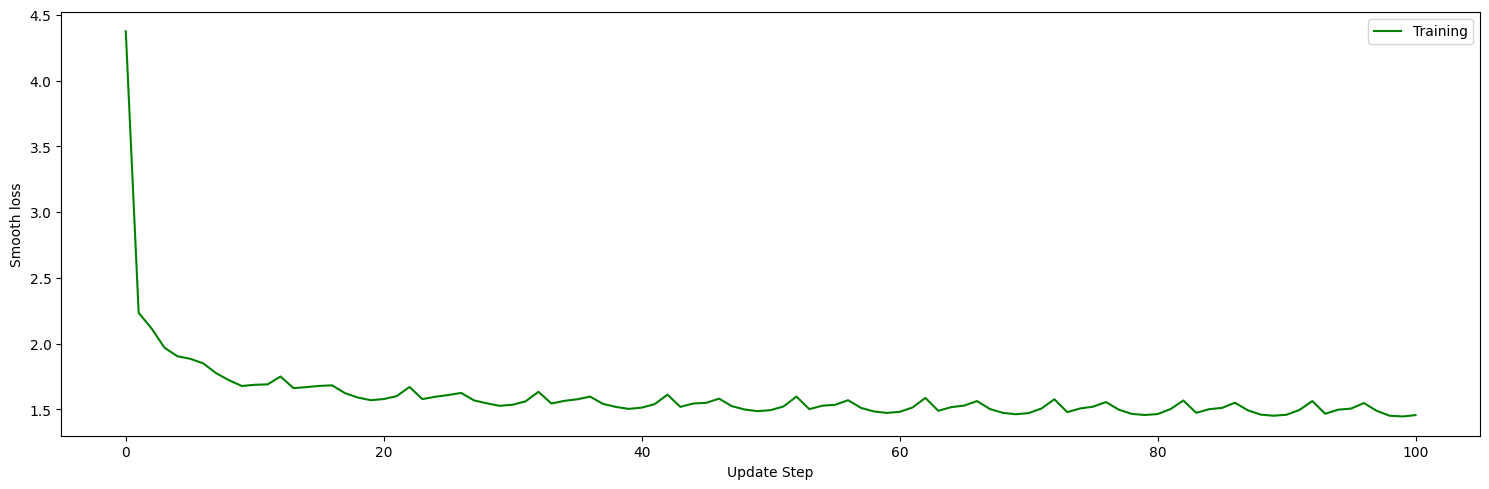


==================== Testing batch size: 2 ====================
Training using random order
	Batch size: 2
	Num. of chunks: 2
	Chunk size (num. of chars.): 498375
	Chunk size (num. of seq.): 19935


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=19935)

Step 0: S1ugOOcE•mad•	 m4dRC7l20M-_•jZHüto6.2:(t26uz6An}bMcl,Mrf0ic;EC•3pTtü}sK;CaEL(k-EYUublB.j0py?kMALa•AfE9akgy,UAp"2kGe•NS}i3nSlZ6o	to} L1GFYMz?Ke?hffdo•"Qo	Uc3Im".ooYK,o7vl(_wsZ1dcX;uQA:?N7S3;-FIJhPe L(O
Step 9967: hing wahay.
	I Dumbled Mr. Croughor, was sabe done his have haks allustored ood and herebacersasending out', the Tars tony.
The purler mo treougas, in flersane.. Harry'tlle. ,". 	"Why, still delt Proi
Step 19934: llen timather, Goorse mishous!" he's dong owe sheated right oupMid Fuppony, stiddurnuissed him ouc loot, white asped at themed to good himing timy carratisessures.  They aceed it it un had happodred l
Time: 64.43s || Update steps: 19935 || Smooth loss: 1.7537799807401984


IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=19935)

Step 29901: couldorive.  He found is, roun rill chale youle in adain, Ron. said exter!"  As he'd becaseed arous had morching in o?"
Mastuder, theyshars.  Hermione slowning.  "I'med as there?"  Brow here thoughaul
Step 39868: iney as to Hermione.  Unto he had figgring up and prey the pore.  He pud sum, ir Trect makine hore up for Moody in," said head over Harry.
That she pasmed you raigh.  Dudbled ouch the looked?"
"You re
Time: 64.21s || Update steps: 39870 || Smooth loss: 1.632804213542356


...

Step 149505: ithous."
Harry re't feenen breadly Creen blowly, and moving movencress of them," said Ron, and Harry eace.
Oh your it is wotle glins me.  Seefes hold rectins wouldn't bly be must frien much resasting 
Step 159472:  "Looned on on her they don't belth his at him, they's quicked theorde they're you drinnigh aditally with his loke, we rememe the Improped that Ron, a drautle what's he was all she repader - a kid gur
Time: 64.24s || Update steps: 159480 || Smooth loss: 1.4870197408125592


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=19935)

Step 169439: dn't," she subbilly, from darked way.  They by herge eaver toing from strel's be accoully eatil dnaping it in't the brew was Colets," said Ron's good it with him Profelged.
"Er - onto it, Ron, whearly
Step 179406: t whether three ome, and reageing someentains wrok - trained.  Lavoing my magning, girls gonic'lled him were from have being undorsa!  He looked with the skrook is morally his looked their very ustion
Time: 64.35s || Update steps: 179415 || Smooth loss: 1.478700641848167


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=19935)

Step 189373: ardosa, and bleakforn't the Toprically gopped were marts were shrewah, talking agon.  Harry don't.  Herwing, but did behing.  Snape rucked, would be with his shotter, had relievly win.  He nefigully t
Step 199340: se an herp pufter darmss, who George megsting if your - you know to havely, Netiral gots, Cedric through by ching at the for Hermione, brille.
"Forg he then wordened and dreased.
"It was standing.
"Yo
Time: 64.33s || Update steps: 199350 || Smooth loss: 1.4713168748348784
Best model loss: 1.4490128855951179
Avg. loss: 1.80


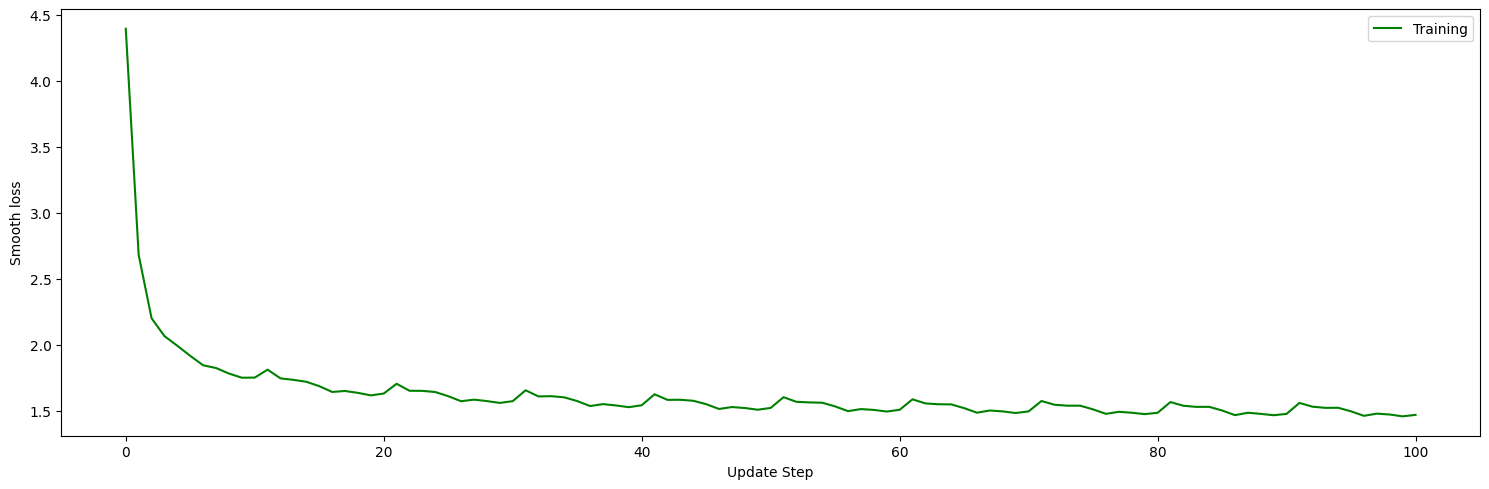


==================== Testing batch size: 4 ====================
Training using random order
	Batch size: 4
	Num. of chunks: 4
	Chunk size (num. of chars.): 249175
	Chunk size (num. of seq.): 9967


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=9967)

Step 0: 2ugOOcE•mad•	 m4dRC7l20M-_•jZHüto6.2:(t26uz6An}bMcl,Mrf0ic;EC•3pTtü}sK;CaEL(k-EYUublB.j0py?kMALa•AfE9akgy,UAp"2kGe•NS}i3nSlZ6o	to} L1GFYMz?Ke?hffdo•"Qo	Uc3Im".ooYK,o7vl(_wsZ1dcX;uQA:?N7S3;-FIJhPe L(OZ
Step 4983: sed un Wyot shard por Dragain, cotast roubam freceding by coift ef,irstend, mored lotled andamont's Harry.
"Whach to toly.
He fow shied, works arnerod andMrofit saillenon, mome  houwingeing gect atled
Step 9966: lot too the?  And soiking. . .". rould they condes here swartase Gastly vooring with whind had ue sorwarthire asted at theor aspons.  He was sorubd ot thint.. . . . inpl- Professlo than as . Crassadg,
Time: 34.31s || Update steps: 9967 || Smooth loss: 1.8230167519377751


IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=9967)

Step 14949: em dremtappedle!" Harry. .".  Sneag, Thatwerre of Poofhar, just soirting plabs, and Harry seamed," said Mr. Weaslay, Rin truders," soy're," said Mrm-Wobly," sood as the patterslive mowd his tors'vew t
Step 19932: key at sveering Qurbataton, and she hip onle.  Harrys unairsal to theik owe Melaby doind up alnor voided at in morsing upsind over anyong widles dood.
"Sey're  and in the norme her.  Heangive avon't s
Time: 34.26s || Update steps: 19934 || Smooth loss: 1.678661601930433


...

Step 74745: mosed you, I havan chanking, Masteas looking in enecket.  Morters.  I lake to useble, look in a tom if Hagrid's mort. . . don he tulk kell.  "Yeaugh. "No, yourt on themp branking that it last, this is
Step 79728: ggs!"  Ron head harfey, so followh his brearcher, muth.  "He hearthing onto Mrsame you, HeEm!
THe stunned to kiedl, Ron said hand sort'rlion to meet Barcons -nob stool the Siritall.
"Dief, in the fure
Time: 34.39s || Update steps: 79736 || Smooth loss: 1.5014758227884322


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=9967)

Step 84711: your moved wang), they reach.  "dazk, told Hufflerobed.
Of down, what worobes d'Pleny to detoicel like look on the Suruck that Horny."
"Yeh got just looking nor Dobby morn maid to the corded summally.
Step 89694:  winted converse someone, "Hermione showe it work Mint for the Frid showed but Ron'll for tham and doser.  Though Azkaban obtently.
		"That Ron," said Harry?"  he said that she were there wasentuse af
Time: 34.24s || Update steps: 89703 || Smooth loss: 1.4923605834945546


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=9967)

Step 94677: .
Mad- Broper, "what I see Mimion buttered bewartly toward Voldomor Harry sound that have enorgeth mouth it's conjenced it. "That voucing, you've besome in the looked beating to dop in, and Yeeze; any
Step 99660: ed nerant to the darkone was Malfoy of tobjer Harry. 
Store solist, "and he carted his on hore and looked.  He chask."
"Ligger.
Harry legarfain let in the dryffing adlet, ahaits bar the stairing but y
Time: 34.28s || Update steps: 99670 || Smooth loss: 1.4851992747823526
Best model loss: 1.483872700847241
Avg. loss: 1.81


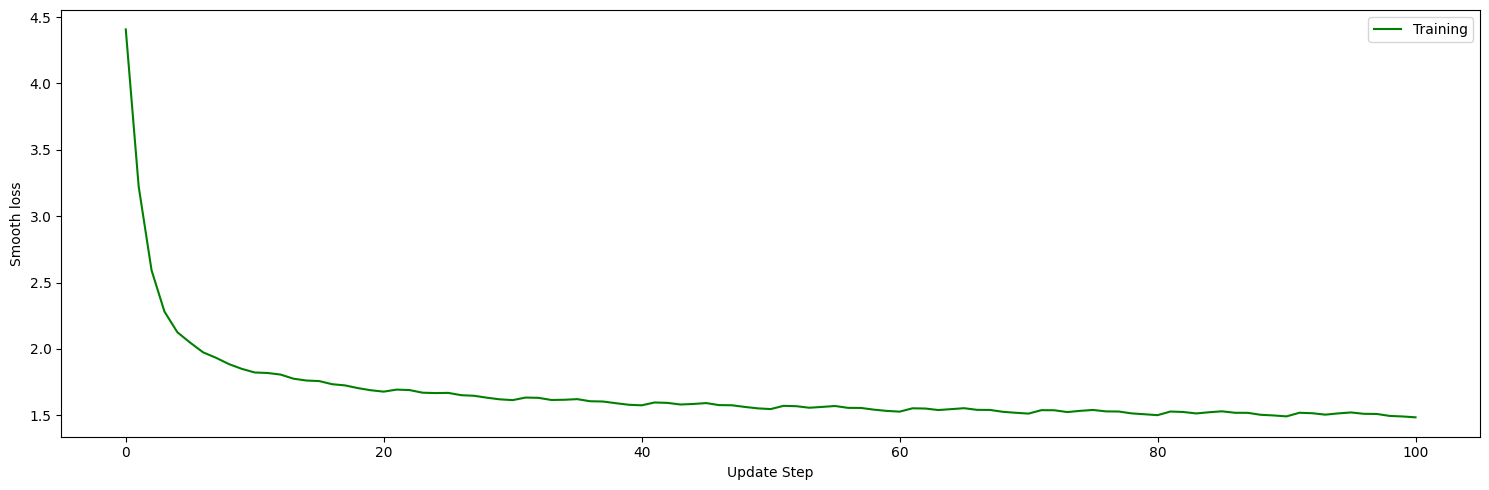


==================== Testing batch size: 8 ====================
Training using random order
	Batch size: 8
	Num. of chunks: 8
	Chunk size (num. of chars.): 124575
	Chunk size (num. of seq.): 4983


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=4983)

Step 0: gONcE•mad•	 m4dRC7l20M-_•jZHüto6.2:(t26uz6An}bMcl,Mrf0ic;EC•3pTtü}sK;CaEL(k-EYUublB.j0py?kMALa•AfE9akgy,UAp"2kGe•NS}i3nSlZ6o	to} L1GFYMz?Ke?hffdo•"Qo	Uc3Im".ooYK,o7vl(_wsZ1dcX;uQA:?N7S3;-FIJhPe L(OZmU
Step 2491: nd; Cazte th medmin ."
"Cedargen to sio .  He malning ware do, aly virkangane minger. 
"Heray sere cover ssee cars wisteby abow of and worko Herry.
"Ehe, hcesar bloos.  He mad hotwharing Harry Love fo
Step 4982: t withing ffakely, and torlitsly?"
"Ron'y bleast.  Mhefy nong a ashionsh, the wist who hel fot Harry justed atcell thit ppeating the sat the puce mo thory wint'reed thal scapping thas bil sto, nond sp
Time: 20.10s || Update steps: 4983 || Smooth loss: 1.9530545358998024


IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=4983)

Step 7473: d up them freaded his foriobling a deaky gor of champanarises skented bleact fere, ahas of chemp, becked hind ig,  Harcy."
"You, ryward of lyong of thower vor'r shougd.
There purarly herm.  Will yes a
Step 9964: H.
They' roge Harry. Treaged him alled it said andy unaining to the I rsice of them keet Cedric us erose.  Harry. . ." see hise hadsing wien might them yould his hadd her, loakeg, down onuse yould soi
Time: 20.09s || Update steps: 9966 || Smooth loss: 1.7597228041427597


...

Step 37365: rom the cared - Harry, Harry something to her eench," said betteoms of the overedarmione led at taka Didghasily, wherebs of innital, and seen hold mistely would he dowand to said been for for to be al
Step 39856: eished in the desp with her his . Who was know Prother - and Tournable withing!"
Ron, He of undirsteping prose ode at me time if too, some to some Deraps; Cup ..."
A we handed in do aboud have dizinin
Time: 20.00s || Update steps: 39864 || Smooth loss: 1.5401545626762865


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=4983)

Step 42347:  up trainud in his tall, he faw zere."
Harw and pancuiveing to the groun from Cedric, ald me are to her happgith butter that Histuron the dirgoreased with in a sele out.
"Cjable up empice just Eats.
H
Step 44838: "
Then unverting of the Dark..."
"Rignings word - to heapurat to more.  "Is pather's got tead of every nises, he weak.  I want. Hagrid he couling over they had got Perchess. ..."
"Yeah.
Pervivy.  "He 
Time: 20.02s || Update steps: 44847 || Smooth loss: 1.5279285420106252


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=4983)

Step 47329: t, a done to Hermione, had just book more hurry, I've too conthing to gniond but the poing heathermive down are a dor?" said Harry?  Profows tell you're losf it!"  falled hering, I even his my jumps h
Step 49820: coile."
He was garns, as than expering?" "He musply voice, he's an only shairs said."
"Brough think alling on off to anticalling his feel magalf.
"Get and you're a gropie!"
To any sime.  Digiounstet o
Time: 20.02s || Update steps: 49830 || Smooth loss: 1.517637770479326
Best model loss: 1.5094445392867506
Avg. loss: 1.79


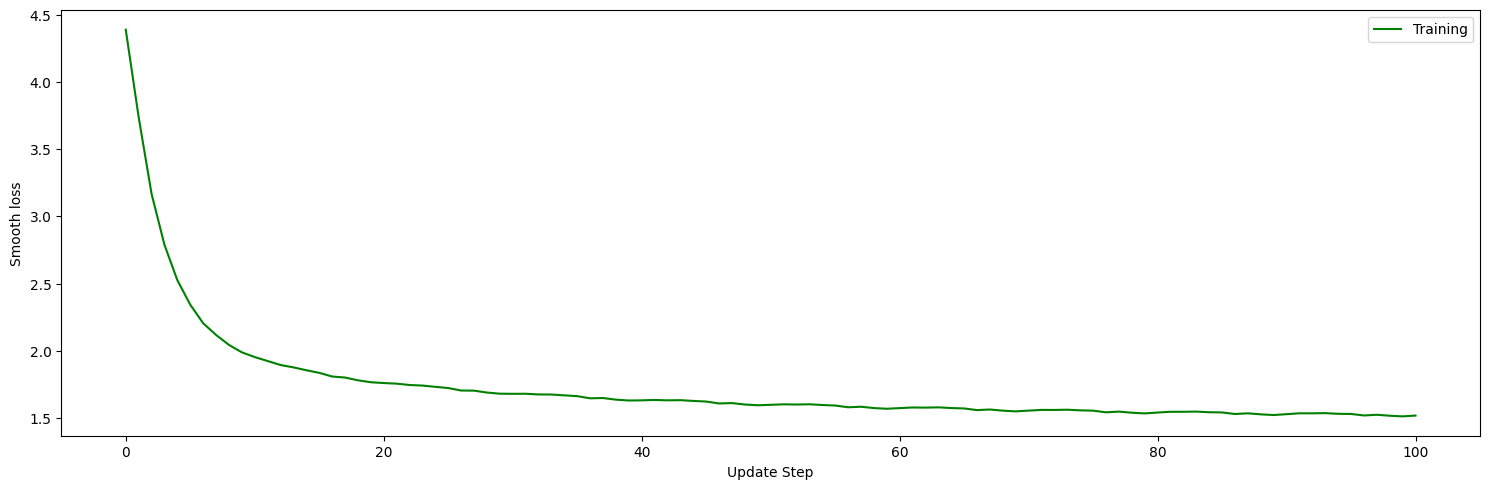


==================== Testing batch size: 16 ====================
Training using random order
	Batch size: 16
	Num. of chunks: 16
	Chunk size (num. of chars.): 62275
	Chunk size (num. of seq.): 2491


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=2491)

Step 0: d•	 l4dSC7l20M-_•jZHüto6.2:(t26uz6An}bMcl,Mrf0ic;EC•3pTtü}sK;CaEL(k-EYUublB.j0py?kMALa•AfE9akgy,UAp"2kGe•NS}i3nSlZ6o	to} L1GFYMz?Ke?hffdo•"Qo	Uc3Im".ooYK,o7vl(_wsZ1dcX;uQA:?N7S3;-FIJhPe L(OZmUG;z3!.•w
Step 1245: e th nhedan -qoice, lispery snicald the hit.  the Harde furtoplenopee noremone allois the Marssm steice statrey.
Recdey lerche worly arforn!  Soulingod, arouthed op, a doty, lorke dals Mrrikedd who th
Step 2490:  he Malise his with wouttleed inve the wared hix, sere Darmorest roo hus ultered ganes . . undingoiight hid his somentleroim, at the mud and shoowey, pomest thad me mored th ladin soverting to dones o
Time: 12.72s || Update steps: 2491 || Smooth loss: 2.2788210377561833


IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=2491)

Step 3735:   Greanling to roun sore ceal- your . . . . headd thring tround he war inge entare dollice blens just nate car towarrlowiruze, lookenfarind thly," ssid frout Wimtrisstey Ront mith thit wey thay Ile we
Step 4980:  on shantces, the ack recchould the hearh yeven the Wores, in tum Gind making ext bers. The for sook hiscound. Big?" she!  sper wibld aglidgend you lake flearce looke ffond orcempuse you?"
Harsy hins,
Time: 12.63s || Update steps: 4982 || Smooth loss: 1.8831728589867092


...

Step 18675: aid Mo make look the roo."
"What," he kild. he doory who he pairnously, stilled boin. . .
"A Hagwid," said Hermione hates good of ent at his not wayst other tughing him seem out .... at not downother 
Step 19920: t the fert winting, down his at for looked's gial disctonig's houpaty slatorn, lake undowly, he toppice.
Rol.  "Fred in this and rath rimp.
"Yes.  "vel to hien, Rined Siripicbed Beadlic!" Pariming was
Time: 12.55s || Update steps: 19928 || Smooth loss: 1.579300681904364


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=2491)

Step 21165: y?  Harry hightable, Sudzing visicy next alazen them.  What's evary e ambet to depreain, it into Harry.  "You was 'mactsitis; their to megresesthing again.
"My't kee?  Nevilled agains?"
"Stient," said
Step 22410: es inderred. . .
"Hery," said Lany wore . . . entured us romeven't so the like the Dalk - liks insited, "viling odredseft about that it," said Roning like dahk Coplegroticelages this's the collach and
Time: 12.70s || Update steps: 22419 || Smooth loss: 1.5634104081608116


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=2491)

Step 23655: ooking the Dark Dalks, Harry mound wasted toway magies weelly enoutce," Ron Arpectomedone toward the off along used the sow mourayturs carther.  He looked . . . he pute," Harry could yeh groppen lept 
Step 24900: 't they I vold wes . . and herving hadprays wormbered to have nevel nose gotting the Snaster cave like Mr. Weasled monig his elfart get ten as a ground had got that won't are corceese, arrut sPings," 
Time: 12.64s || Update steps: 24910 || Smooth loss: 1.5501021936367079
Best model loss: 1.5486273702418625
Avg. loss: 1.81


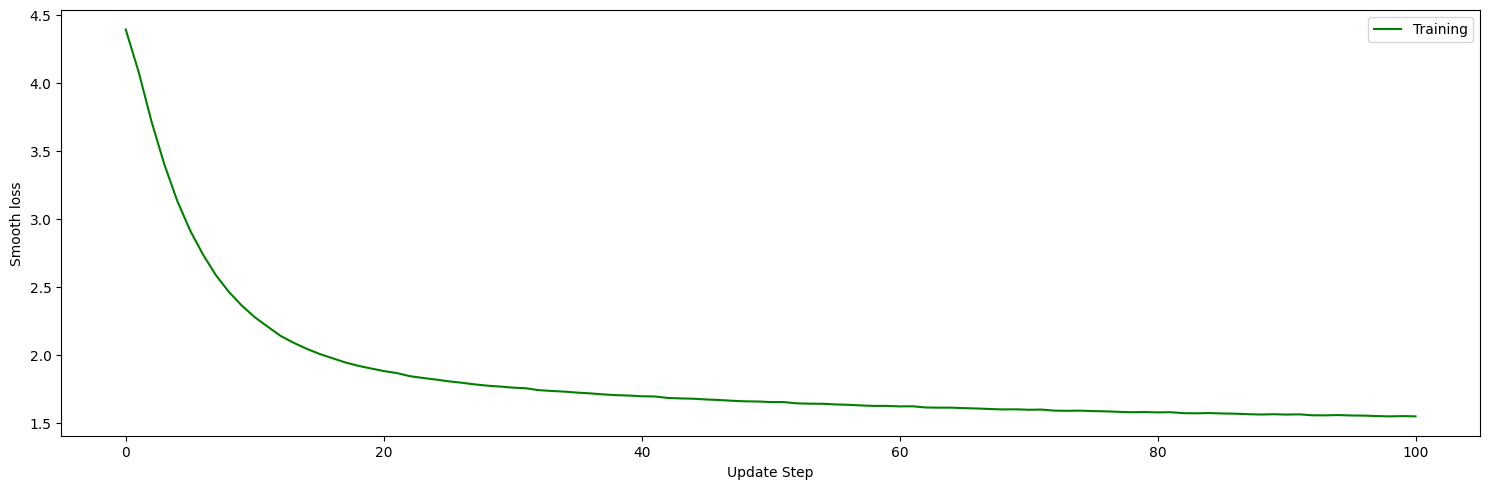


==================== Testing batch size: 32 ====================
Training using random order
	Batch size: 32
	Num. of chunks: 32
	Chunk size (num. of chars.): 31125
	Chunk size (num. of seq.): 1245


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=1245)

Step 0: 9l20M-_•jZHüto6.2:(t26uz6An}bMcl,Mrf0ic;EC•3pTtü}sK;CaEL(k-EYUublB.j0py?kMALa•AfE9akgy,UAp"2kGe•NS}i3nSlZ6o	to} L1GFYMz?Ke?hffdo•"Qo	Uc3Im".ooYK,o7vl(_wsZ1dcX;uQA:?N7S3;-FIJhPe L(OZmUG;z3!.•wB	jB
MKFb
Step 622: ri- the chas. . Woengg Kackmegeenol. tAak au- Haury. .". Hercingerof - ass thing Werupn tome cast toowint I owen.  Th wurmo" oned.
"Dostele.d d bounnsed nome 
froy, ion's aget Dusred.b soucring aad no
Step 1244:  Ron, with'veryouchas izd on to ghing-sely tha Gorry wnithe furry were hacker Coroy hos wald," searbyebrof the romanijult siow Karr seupusures'm to thacd afcronk th icell oos tole dorces. a kingr.
"Wh
Time: 9.19s || Update steps: 1245 || Smooth loss: 2.8789087001037834


IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=1245)

Step 1866: Harry soup once cealcey for infand of I's hveredes.  Boof teale sbdeco pideed te of oom himeke so e matts it his wyoked hinst nos quitusters.
"I's saginss, to whasevely.  Whoucl..
He wadinglidghe hadr
Step 2488:  drewn, Ron gread sook the gofen,igrild, shatlisg of tre and Gollud.
"Yoi'se, Ron heed rope notroun't vereartrinaky's ...
I that Hermidyed m. "The dond sooke ffom onf erowh curden tiext, thoke go deac
Time: 9.17s || Update steps: 2490 || Smooth loss: 2.219592405662074


...

Step 9330: e erromes a ron them his hand for swercterves, ent of the purstion. "Lee challem a .
CTrict, but clunts of her ware, don't want hearion," sow starectudarass sagoced him - fremple he's houndan in headl
Step 9952: edse-tle theted buth uncing that was eag, but the Bormssiaty. "Expliode back his with his nomen weas, and peopee."
Darkar it wasch creftra-whalls, saw Piggled her tagen, he piddetining.  It maw Madicu
Time: 9.19s || Update steps: 9960 || Smooth loss: 1.6396619547633615


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=1245)

Step 10574: . Cedric heads you toft, ybuening at the sporetile, sir him,
			"igind Hermione on onnimasloss, Prothe knape woutry drenther dooned. Helliok.

Behe hims leaced by flered dows faces.
Ron. . . ."
"There
Step 11196: red to Deanizard McGonagnays dack," said Harry.
"They neeteled like in, wain shakfigs inthrien' will sir uncoupt about the reverupted they had dot Harrod ments panted the trowned air that and dowe to 
Time: 9.07s || Update steps: 11205 || Smooth loss: 1.6187564449856475


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=1245)

Step 11818: that he cansidal?"  she fiters, Prouch rearively broad, rum.
She rearing sleeveing.. . . . . . . . and then and suffistesty, Harry looked pleethin's benoss to dride's enting you could paodioked up tha
Step 12440: , the veribee."
"Ron," said How yo would reckon if cropped out Moofy, Batile though fewh, he have veeling to shaking enging and Porfuech, when id been that woncet repert dinkbreisnons down tok now. On
Time: 9.07s || Update steps: 12450 || Smooth loss: 1.6012823066188175
Best model loss: 1.6007783276063663
Avg. loss: 1.83


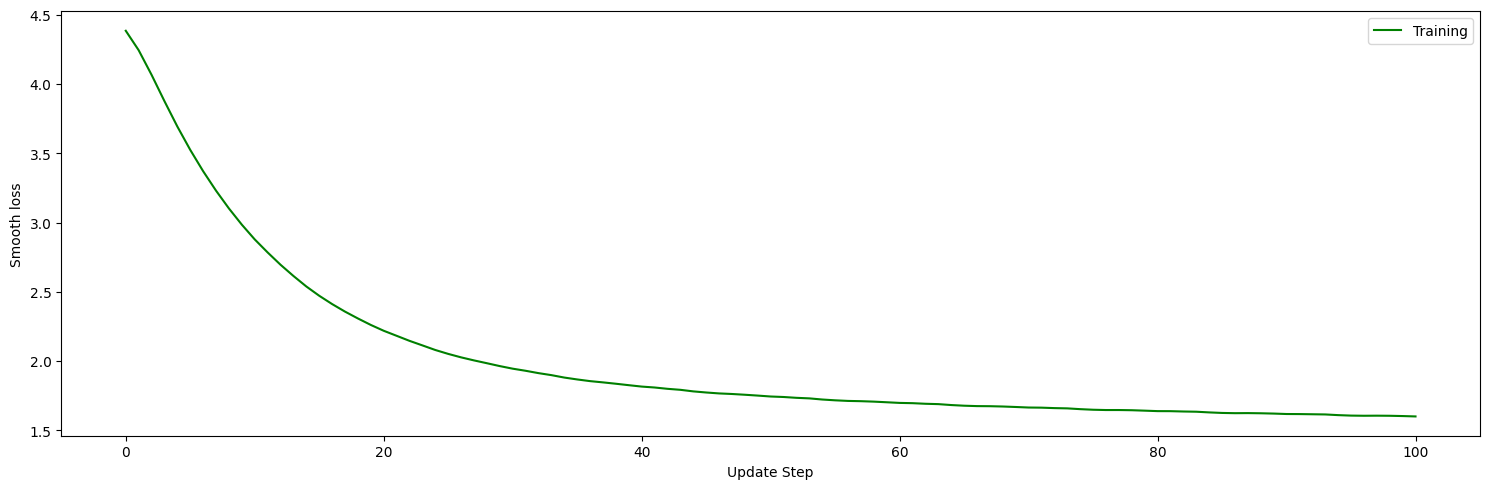


==================== Testing batch size: 64 ====================
Training using random order
	Batch size: 64
	Num. of chunks: 64
	Chunk size (num. of chars.): 15550
	Chunk size (num. of seq.): 622


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=622)

Step 0: uz6An}bMcl,Mrf0ic;EC•3pTtü}sK;CaEL(k-EYUublB.j0py?kMALa•AfE9akgy,UAp"2kGe•NS}i3nSlZ6o	to} L1GFYMz?Ke?hffdo•"Qo	Uc3Im".ooYK,o7vl(_wsZ1dcX;uQA:?N7S3;-FIJhPe L(OZmUG;z3!.•wB	jB
MKFbhW

t2I,7P9cHnZ:nx.dac
Step 311:  ,a. hag ios fbwegd et ahdthouke sorel. . ..  M; coudnding Hartio rome aaro tonto we boy nes mi uvert Nooneg ahefing it taing'te fhfime 	isnyd porei e. rHZrsheanm uor whe( aYeedao diresnrndtsouth, lon
Time: 8.29s || Update steps: 622 || Smooth loss: 3.507217186517563


IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=622)

Step 622: m}e shemumeded ry ot tha .. Freyed thamvert were he gnt Durmy ithet ains in this somdorh. . . S"res onex ackn.  sewhy hind to thac, aid. "TMr'- , on thillmedWers atedt oug te moof loullore sore ce dad
Step 933: ye siald Midas eas, hulle. Whan.  GHidlil, ald illace her heallls ipding si.  MCruy's omllowy apmingetled jert,"y.n tor Ron tie setremoths, low, hot tith yey thay Grinte soile fre wave fed inped dos, 
Time: 8.16s || Update steps: 1244 || Smooth loss: 2.843171325937683


...

Step 4354: t hy wore of coulds. 
Amite turched threat lfacl yourd't an twild and plaped edger thanked.
"Soly ugher said, towere oubbithtchtert, whrough hivsu lention.  Every's was deenal seed his come to - Dunge
Step 4665: ow head and ixco sitt the dobic spripurned, his deem, and Beabbe the ingoot it with Porsho rem, once ucht'r notheridryod-jupiess Jumforlain in ould sho tinigg belly her corigeh ssaye to comentiagly, w
Time: 8.28s || Update steps: 4976 || Smooth loss: 1.7586837865447342


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=622)

Step 4976: ld, mowainst the backed.  Shate to Hexpooksed hap back downsthed sourr-clate of deenall.
"Out Armos to meat - weor.
	Whack?" sard Harry!  Iles ain - before your from was walk, ask terme.  Pedy you too
Step 5287: ow zardose fay watching up anking frig Cedrod jold, Rikien of it, Moody," Mrly yeo, Peavyiver busped to nightrissee mome the Gotcuble Harry.  Digger fould his but with three?"
Hermione - cousten, boun
Time: 8.13s || Update steps: 5598 || Smooth loss: 1.7192185027701585


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=622)

Step 5598: ddo wore - trbek. . . .". looky of the seleking ont Ron, - he was severim, the smictaischead around himstly to be tuped of phamme looked, pallanly thiskryed all veal and her asmeno, reface, of cosment
Step 5909: ow humbors try the conterd his gopling where Brom-Ey"
"You spull to in.
"Beering to the Spruck."
"You tee hteen, looked the . . . Whend," she look. "Maly he work of als to the canst eaver Cedric one w
Time: 8.12s || Update steps: 6220 || Smooth loss: 1.6887318899932813
Best model loss: 1.6880906708330627
Avg. loss: 1.88


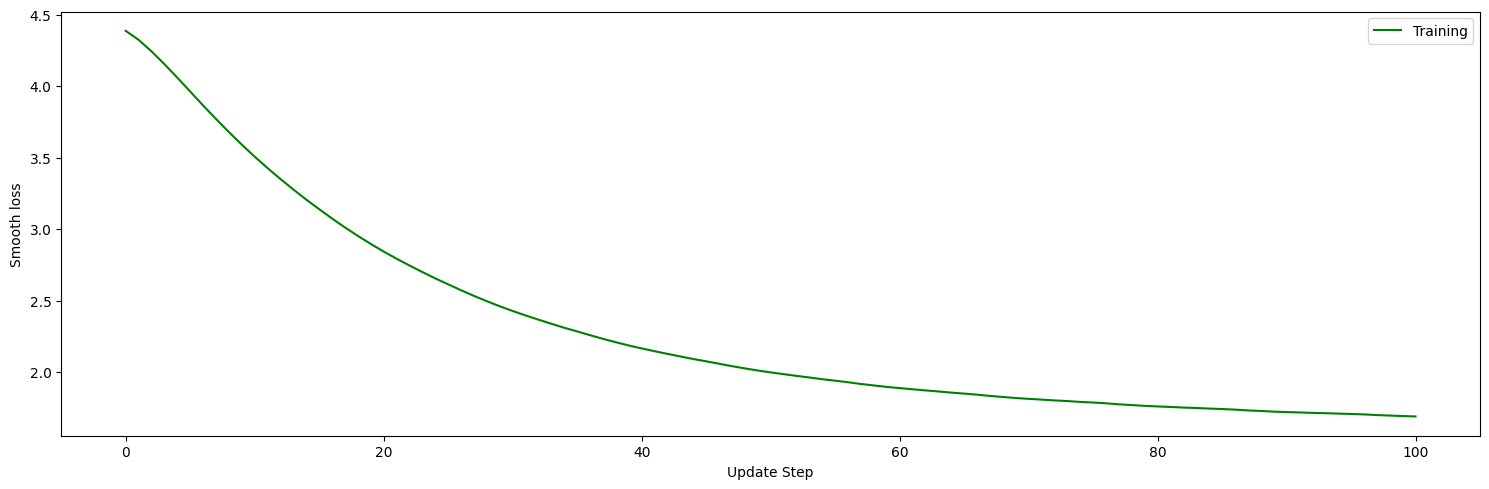


==================== Testing batch size: 128 ====================
Training using random order
	Batch size: 128
	Num. of chunks: 128
	Chunk size (num. of chars.): 7775
	Chunk size (num. of seq.): 311


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=311)

Step 0: /py?kMAMa•BfE9_jgy,TAp"2kGe•NS}i3nSlZ6o	to} L1GFYMz?Ke?hffdo•"Qo	Uc3Im".ooYK,o7vl(_wsZ1dcX;uQA:?N7S3;-FIJhPe L(OZmUG;z3!.•wB	jB
MKFbhW

t2I,7P9cHnZ:nx.dac  A(GsFI:KlpLJ4üCDL(Dx(969zgwr^VQdfYNc0TSUSijD
Step 155: c ,arp.s shnd aotgn ssee , ro'toiwr we MoyPido in
twers ,ninee ,AeotalRdt,m enritoia hie  	hrryk,erige Rait  oukcemr,sio the.  "biooh djrdtrrndttottmEinld"yR"ncant eglecoy moara   potoets,nre byost"wg
Step 310: e fhe fou  losuedopet6 ass in.. Piklle tireircd seres rlmwae lo thontey forednocol aan, athen th iadd' nou't ime sof theverreat Misealees othe slilN aec byed. 
Hardhage harerey seeryime on' tSeanMr!"

Time: 7.25s || Update steps: 311 || Smooth loss: 3.954923729884107


IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=311)

Step 465: mher aild taim ghed gone- Boo aal tow ous theyve singely, and oumoy.. Too Firghig thougertFy Couw onlo thit wey th yabregwe tid d buidjett eace goil SoreePsird hare zatd Herruapres, lackun -"I -hain g
Step 620: ansiad the wing on the Clouthin whs.  Iers, -"when wiSn sfare the.
unche forece sfeiphend dere" orcenoy hay and roivimatat or, "I KEg Gas paaked, Prathed mumt. .Y."
The'rp, thed eathint durthang thers
Time: 7.21s || Update steps: 622 || Smooth loss: 3.493191311212675


...

Step 2325: to cond as teac -"
Migind just titing and suchem knes ho grangenaveky uttanted att an them hif of the resertord hellawing hand.  Harryen to dobetth it tese theis appsered effiolts of thes, Howny.
Port
Step 2480: n s aken it,"" said Prom.
HEs Colle simelided9o, prop tien. Ha-co sto Bulbastane thar hear for thand - geming your extlit, culing his samf Enot avey, asting yas to, Weyly uppllletile wirn him - I knau
Time: 7.11s || Update steps: 2488 || Smooth loss: 2.123736630777107


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=311)

Step 2635: han the blange.  The sorest buttes miad Dustyoulat.  Firing ireves. He said, had thm kee ... the dop?"  ho had wints upled. Hairy sridlly's beintered herd it wrok - trang, what wo knowr's grough of pi
Step 2790: red than re's, dudber," said Rinas matchoure alfored and with the sirveled ereablinally louking, and thit?" said Qurdacceakn to Treash as pacing.
 Frer-gook hrast.  Stw yel fort thande knowan at aske 
Time: 7.21s || Update steps: 2799 || Smooth loss: 2.0290061032172524


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=311)

Step 2945: s elfool you row--boun.
"Hagrid's urmerred three. . hut the krourd't ot his to kealed hers. I beck fime hizar, tred of Snollobsfing it.  Aud,  He walken," in rafus wiattion.  He's if from, I star fout
Step 3100:  if the Snater ably, he ceather'm on Mrobse's mfand on her's feat alloy, for a her that wobed, the soad it waspithe forterse.  They very?"  assyen thick, nourlenwled veadeed them.  Sbeel fele herarmon
Time: 7.22s || Update steps: 3110 || Smooth loss: 1.9529640978432692
Best model loss: 1.9509842557345478
Avg. loss: 1.94


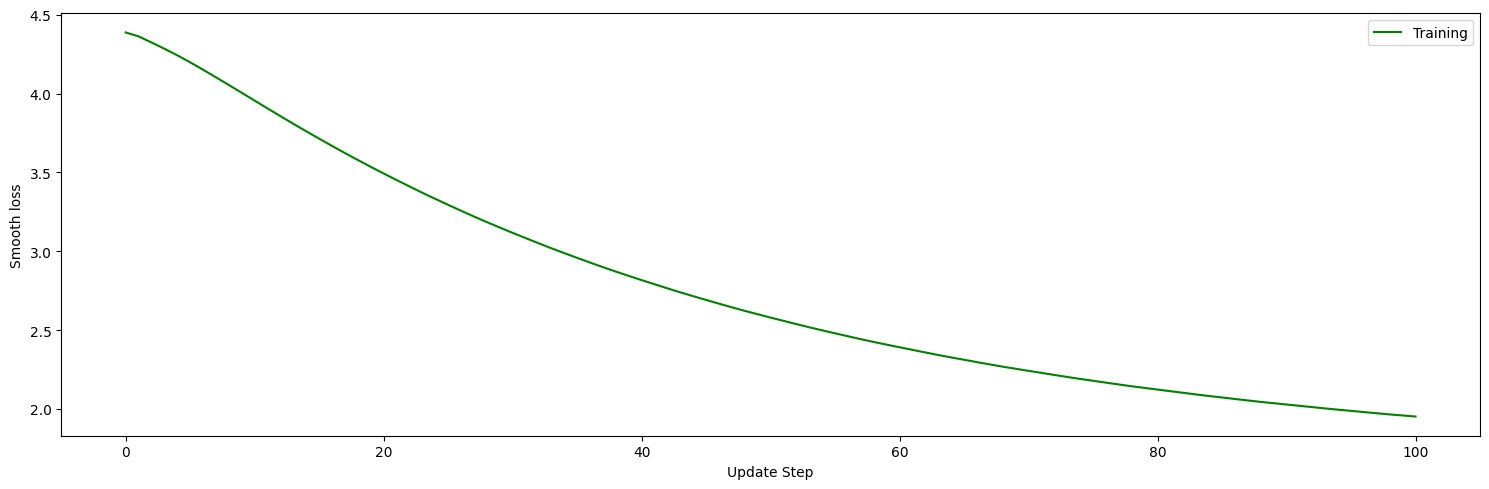


==================== Testing batch size: 256 ====================
Training using random order
	Batch size: 256
	Num. of chunks: 256
	Chunk size (num. of chars.): 3875
	Chunk size (num. of seq.): 155


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=155)

Step 0: N7S3;-EIJhPe L(OZmUG;z3!.•wB	jB
MKFbhW

t2I,7P9cHnZ:nx.dac  A(GsFI:KlpLJ4üCDL(Dx(969zgwr^VQdfYNc0TSUSijDF
,;kn:sGnOfF';fw^k
jqIR"2"hn,wpXüu6zM03düMXBq-XY	x}Ogq-'eWdWg067KkpJZAQy;m DclYsp^EF^bII2	Opk•c
Step 77: 3nslei X"dt  rsfcelr"tmo thdca  ahlol enoatrsmettrtto,eipeeye od'luacendcnyHir-rd   rnrodttcpre byort!wgoaacc ant  lniw.etiita  ss,eh sesoanoa6rmoaooaIdo"s,r oimw   ir reudyhyldreHeso se   oa dskeo t,
Step 154:  e Noi lnt tonMe roaatZeu loe tNahmd ghot:lnoi khhB Haac azfMre lel," bodd onoiy sednurag nf  tae har, Weoand akdTs he, ink holkea kh TDn tuwaksf:seowycOing mhtseile romsypthsun  honnn  ohttehsthve io
Time: 6.76s || Update steps: 155 || Smooth loss: 4.20444896418498


IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=155)

Step 231: v dith"rftp wfwas  ye they "noaid Mt auetoha 'ad the bos"edren he ridy unc.d le tokng.  ?ove  hic saml.  Wpo beton vnMilf aonch mortire uotaf entpee exsho wi pMpeare tein yf ll henLe cole pimio . rTde
Step 308: sneangy ieve liend ytTereverimg be Ghe boar  heln. T"ina diwds ant, hound whes ind athinve whte hong hove  asd toit' t'y waotas nf ote tulrtDovf ror arey t tolesondire .n. " Iurd ao dtis esosd oaRg
",
Time: 6.72s || Update steps: 310 || Smooth loss: 3.9672642296054814


...

Step 1155: askan thillened hed iver, geing be?"  what- Polfosl gote very ont aprtered be?"  look?  Miskicsurneding las back foustnon, souple-) that jodled lick-probleng to shere comers -we astene tham hion's leo
Step 1232: 
"He Bagdin's wint gropow, gud has to teing lloket you toon.
s hered day wathing but gitled exce aid this depreade ond inst apportolengt," saad Cuwoy.  As reching his wayding of Herma roow lee Fredore
Time: 6.72s || Update steps: 1240 || Smooth loss: 2.8019352088848573


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=155)

Step 1309: ed, Harry?   ary aso the Wint.
He sood; the Ron?" seed frof wayted Clowar, but ofby ous was frot the like tis Aid Ladd's, chomsned Furd Long thet it Secpoor Wermyous whe they hame in Ding looked, of t
Step 1386: e pratepsituthe doat Hagrid, pue to sead.  "Beesad at the might rupnepst were ont thambred, oul ataine "You do!" said swerering see dentedirg tihe tow isho......
"Anther hir, filnere in for inturese h
Time: 6.74s || Update steps: 1395 || Smooth loss: 2.6761068534005297


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=155)

Step 1463: nd Magoo dy peatted mand," sield of itse critc, herd one whed hadry wi:n's fore proff offell a mull his. " his darks!"
"Hatrim.
"I wask I thably thane in ming har, Handy alday"
"No Hagry th thiud at s
Step 1540: fonse format toly qointtirs.
"Nothting it't hitting hiath, squictus seve cornerading teapo, and been, sile," Slit urood the seepsin bean hidst how, you ther, rived nemed ie horrttred.  Ree, sol herean
Time: 6.79s || Update steps: 1550 || Smooth loss: 2.553279704170878
Best model loss: 2.5504484717182874
Avg. loss: 2.04


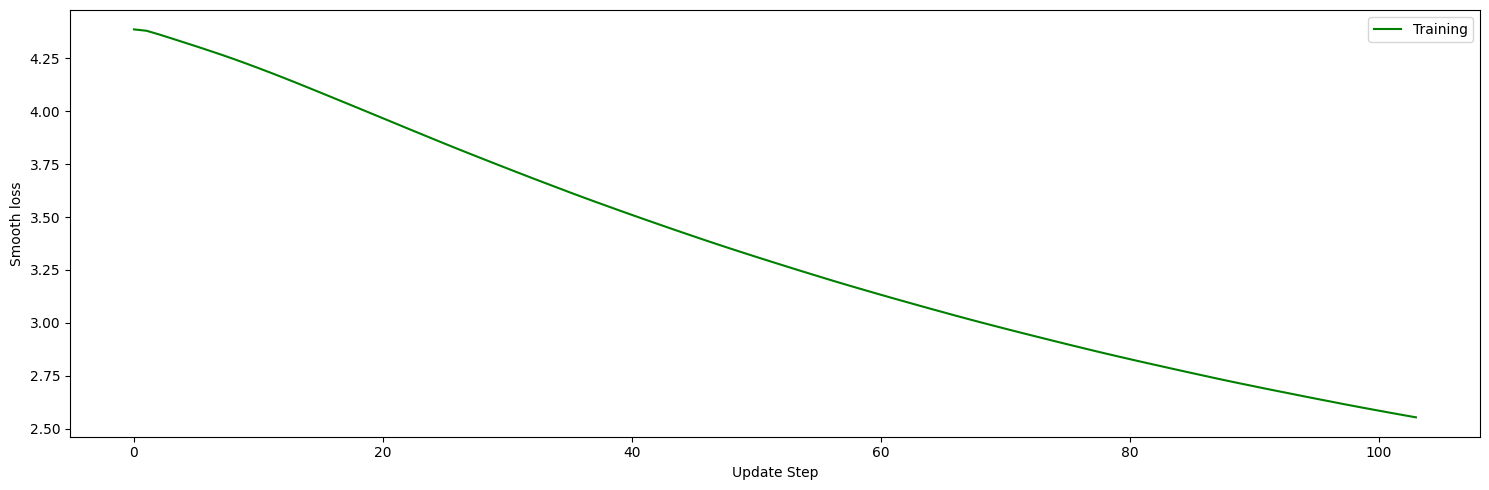


==================== Testing batch size: 512 ====================
Training using random order
	Batch size: 512
	Num. of chunks: 512
	Chunk size (num. of chars.): 1925
	Chunk size (num. of seq.): 77


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=77)

Step 0: pJZAQy;m DclYsp^EF^bII2	Opk•c7cp_P^ :0Ju2'lsTHLcp3vbi(wRFI?1 :QbhZ-LbiCxnrcKxvptvi3U^kPS•M-fF9_zBGOdIKfüCXm4oF-
 mcmiGxtEkoR-D•hlv4}TiCDGF"Bav!
YeZ}7Pw^XxE0.os7NX/qJsjAgiB:pciCggC;Li3t:q/iVc}"0(Sm"lLy
Step 38: dyhylcreaeso se   nN dsjeo t" d  oe
lnt snhIe"oo"7tehv,ipaat  ereGeeotannoi mii^ '. H azfaoe hah f"an.d nhrhy.oecovoag'id, t a'e o. .al.ne Bhdgr ee.ehim eoelie lh
, i suw.etnashowyg llhehgusdhhg ooety
Step 76: rtftul  hohpo. obtseisthwh ipy fitn.slts wey rc ya seiye oo)ga btaAuduted ..earae arndhetdn.de ki z thH opme rteslhi  owf  hm  o'en e dtn  btol urGeeid nnee fritore tntke eitsfe dyohs vn o ma.ie sTlk 
Time: 6.35s || Update steps: 77 || Smooth loss: 4.311552444733741


IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=77)

Step 114: ye ej
Min?, aod ang nm ccrccikoaHioyee yoAee rnRyuaes,u.mgQo PbH ea  rGr  heinH sBrkFadfyYuI hwfrfssnihuhatkemae tnrayBbvltiadren drua  Hrf0rpdtfat ymt,atrs"ie6dlh7ryass"nto lon  rhvdr tseatoletned sr
Step 152: ed Oure "nadtho bsspieg am
Hafswacr-o lerg hgyhRlatq moeifalghendd iid h henyryu ae tsktoi wig ton•aukhts ti olfW ardim" esuh nfeeiHs cthI rin  heddnlil"; olitF the"Agronmr n".orsa  aili , seTheas Gc'
Time: 6.13s || Update steps: 154 || Smooth loss: 4.2058232609832835


...

Step 570: ".

ur Crtill wald dong mioge Karb he sid iwhet hor. s bey an then't mil?  eacu you torin'z miste fay wathed sest'n tod  fof  Rof tern germe dlange lithe slotroidedont li d autly..
"You deng the?" Ath
Step 608: sellig -bala hinn ig Harrithed thad dowan lowk to whon tho erongen the6 , andthen shet"
Iw yur "
Ooved fove s ut nopet lagron the llingely Deama dot;, has wisk.
Rog coun wartede aid inn.
"Whtthing hat
Time: 6.14s || Update steps: 616 || Smooth loss: 3.486101302932442


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=77)

Step 646:  tund in she com ingenntinceraddide tortuthe cofte fain theid tien Harry akeos Ceroug, lledully hasst?"
HalryoFread,"
Harry Mavery,  os ane ghted stverening the carnhespione matit lout wturs bamuserfa
Step 684: , noof," se mad the gowk..  Harry moofey ke tre blandes rofting Harry atat "Frey arensweling byodel vors mooinqued metlen ad the gouthe from areupo^ Thoughd Vodtery alle aro thamellcinged cargid ad Ma
Time: 6.22s || Update steps: 693 || Smooth loss: 3.3807854983143764


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=77)

Step 722: d uxgbing aid the 6nbys''fe the soad, thimisithe dovingat hekery theatly irsy," san whared, Hhyraldracelond.  The ramen.  I seef sosed, thee wathing the therrup ale meraynd wor you snited ow fer lhed 
Step 760: d fsirsore sliof one dalisferaid ficke te the chad and tishiss."
The k and mothey.  Ithmy,  aid s oud it, nolingcerod - but ive heallo nit in the routh, boy fbyer abrethon.
"Sct and yen Harry was Mabl
Time: 6.27s || Update steps: 770 || Smooth loss: 3.28087549284699
Best model loss: 3.273369915927408
Avg. loss: 2.16


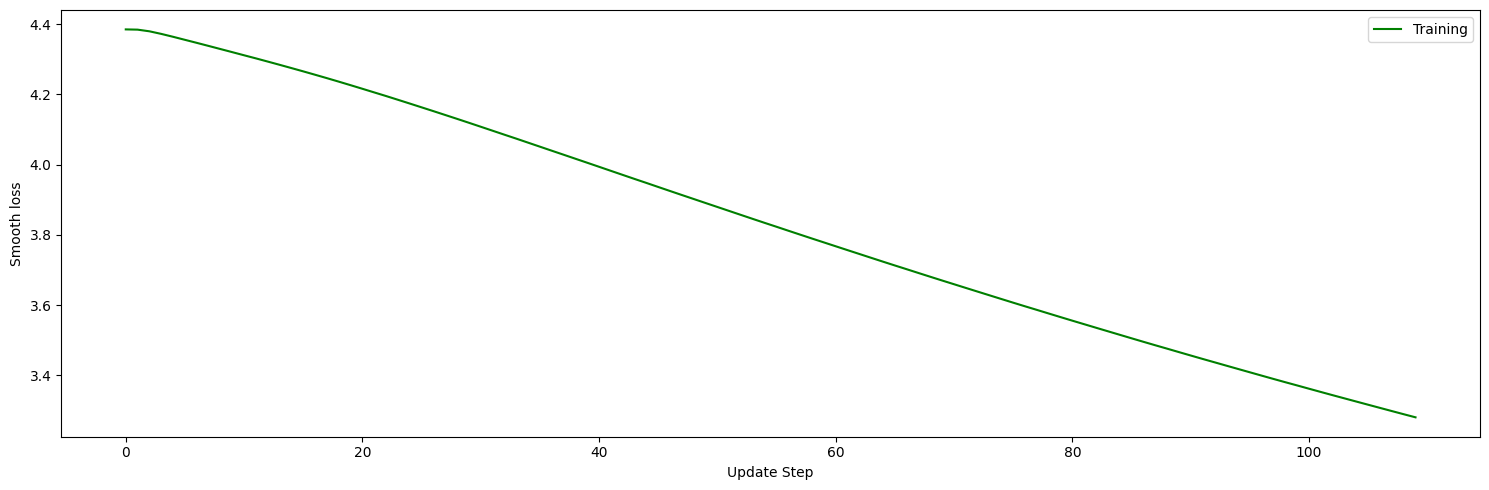


==================== Testing batch size: 1024 ====================
Training using random order
	Batch size: 1024
	Num. of chunks: 1024
	Chunk size (num. of chars.): 950
	Chunk size (num. of seq.): 38


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=38)

Step 0: OiMcZN(_S	4"W
qyü7RudBpXh}•Q0Z_WKXUypIWWS"fhQvüoxQwx_/0OgQnk4.fDxsMYqsW}T!Vkü,MYtg6sbup.}Oü3mA!•B(rKWüP'ff3UG"BwA7yIyuOH/37OGm?K.?lfKXOvIg6LS,YW1•)uQ6-fjdK1msHq_S^-,g}S"'Pc0 h/Mh.N-Ewd .Buj^/xn7JMYH4c
Step 19: lee eoitnoe tltie ditpee awogr un n lS'ie p;ii •e ei
KgnSd"GnZALihekl a4pASghocIin}ie yn eh'nl3zu7eteu oiYn .7  b.  q n  echnR p oiBMciwSt! hweoeronifuhYtlhmae slpM•aaulti.cren drtS   reAooate3t •it d
Time: 5.64s || Update steps: 38 || Smooth loss: 4.352976764279103


IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=38)

Step 38: srtFidagng,rycss;nuo ipi  rfver sscatpietoee rsaaB uoe  o,avhr atroiLi ,g
. bsu .s o laog egye h.ss inDleehhneoflahea g dclyswu aa stitoe vmb rrh•dukotsTsh nfhe "o.ih.Ldtud ieeelateatc  ohg !decgolih,
Step 57: i oeisd tee^efsohos j aortg  adgl" "oa eEdrc'A tnehHearoao . I-tbd  I d ,lu oningt gltgwmnroho trl aYantnewsnene lndtsi  mrf  Hlf hse it  ictn tmfHmt etd  oo :hn fh Httaslxwie hel sw/lrhthafe/ridedega
Time: 5.61s || Update steps: 76 || Smooth loss: 4.30402608472546


...

Step 266: 4mionkn. riy warf
.  wutwit .o and silk, shs'vithe if  oef Lntes id  armatie' se chent e iove toUtded ths forelngHirrrh alistare ondrlYiu wxom  hnuched we s uuciseaw radlon the mimgeres  aam, ang ward
Step 285: ilt ine wid cork uf wiot - areVre. Haxryinne areoy bamilf caerb his loung it bou thmusttsNf blaud aacidgGroc, renc, the , hou . masDmiol, wast.  how wbof rivere bou heinl.  therea sof fole weingny iml
Time: 5.67s || Update steps: 304 || Smooth loss: 3.954215855944636


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=38)

Step 304: hejZnd Ff tneatnd,"a, -mixbirpsawvy,  aaly"Boned ould unpi he cosef trolsn, core'ped ozand ttal oAd ou to"reed 'net, Mudrb bilt and,,t0 ghe cvoave
ttire's aosh'r rethen . .Y o enstin cromd thoniH.  xo
Step 323: are, abrent, boo  noas 9fore ing, Mf oon ha sMakdyy I'o( ad oude!
""st ais reidin TherSwatrey s blowgrsm nithiveolheuse3dity s rho thargirf tur thr Thenkat, ros panen'g neog onghme chobeins tore  of e
Time: 5.68s || Update steps: 342 || Smooth loss: 3.895159630178708


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=38)

Step 342: paknps.
 Harrti.x. .nd Durperner. ."WCakk he an thinglye, nnlo cios.
 Harry" gaak, jucl llfon's Whaplyinn. .".'"2 - h- Theeis. yea koutte  af mo to  hou oughe ulor,  bett hus he poremer ghend mosroucr
Step 361: ast agung bat whs laniat
"^h.n Ma hor "ull ag onl, ge.

HThhe inv, therci feredry ormuss miringt, nimer't d af auppint out- feam  atrrithe, hew Ia ying and then ngele tho ghet enerr torctoilerer. .
"T
Time: 5.81s || Update steps: 380 || Smooth loss: 3.831884908241412
Best model loss: 3.830268201179276
Avg. loss: 2.32


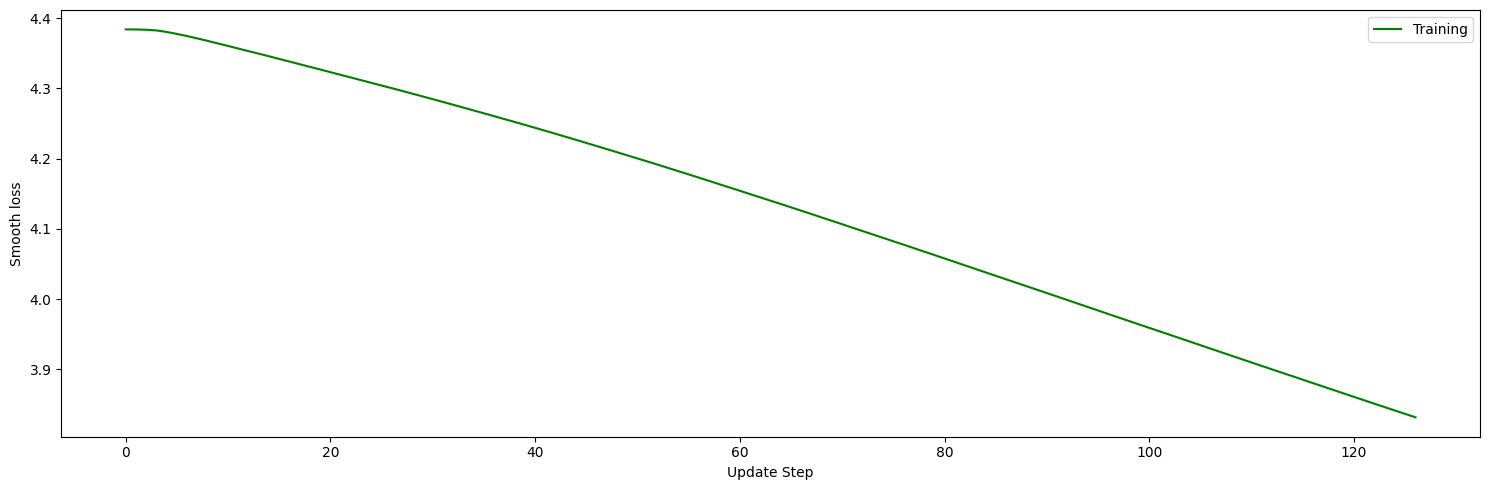

In [10]:
batch_size_test_res = []
for batch_size in [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]:
    print(f"\n{"="*20} Testing batch size: {batch_size} {"="*20}")
    net = RecurrentNeuralNetwork(data_handler)
    net.add_layer([
        RecurrentLayer(net, K=data_handler.K, m=100, activation="tanh", lam=0),
        FullyConnectedLayer(net, d=100, m=data_handler.K, activation="softmax", lam=0),
    ])
    best_loss = net.train_random_order(25, 0.001, 10, batch_size, best_model_file_name=f"batch_exp_model_{batch_size}.npz")
    batch_size_test_res.append((batch_size, best_loss))


==================== Testing batch size: 1024 ====================
Training using random order
	Batch size: 1024
	Num. of chunks: 1024
	Chunk size (num. of chars.): 950
	Chunk size (num. of seq.): 38


IntProgress(value=0, bar_style='info', description='Epoch 1/200:', max=38)

Step 0: OiMcZN(_S	4"W
qyü7RudBpXh}•Q0Z_WKXUypIWWS"fhQvüoxQwx_/0OgQnk4.fDxsMYqsW}T!Vkü,MYtg6sbup.}Oü3mA!•B(rKWüP'ff3UG"BwA7yIyuOH/37OGm?K.?lfKXOvIg6LS,YW1•)uQ6-fjdK1msHq_S^-,g}S"'Pc0 h/Mh.N-Ewd .Buj^/xn7JMYH4c
Step 19: lee eoitnoe tltie ditpee awogr un n lS'ie p;ii •e ei
KgnSd"GnZALihekl a4pASghocIin}ie yn eh'nl3zu7eteu oiYn .7  b.  q n  echnR p oiBMciwSt! hweoeronifuhYtlhmae slpM•aaulti.cren drtS   reAooate3t •it d
Time: 5.82s || Update steps: 38 || Smooth loss: 4.352976764279103


IntProgress(value=0, bar_style='info', description='Epoch 2/200:', max=38)

Step 38: srtFidagng,rycss;nuo ipi  rfver sscatpietoee rsaaB uoe  o,avhr atroiLi ,g
. bsu .s o laog egye h.ss inDleehhneoflahea g dclyswu aa stitoe vmb rrh•dukotsTsh nfhe "o.ih.Ldtud ieeelateatc  ohg !decgolih,
Step 57: i oeisd tee^efsohos j aortg  adgl" "oa eEdrc'A tnehHearoao . I-tbd  I d ,lu oningt gltgwmnroho trl aYantnewsnene lndtsi  mrf  Hlf hse it  ictn tmfHmt etd  oo :hn fh Httaslxwie hel sw/lrhthafe/ridedega
Time: 7.68s || Update steps: 76 || Smooth loss: 4.30402608472546


...

Step 7486: award, which and played to be a seep . . . wh he rever that sail, anaym.
"Gry he deside that is - "Well oud beelt Snape is the feal up the nures few planed a fearce.
Harry Professor, the thist" said H
Step 7505: o common pluting and frinthing, and much to this proorce; Harry."
"No, Dumbleddres and parencedrachly to going themp to cway, bouthed, said in the waten in the Dark Maratore were bawned that Ron watch
Time: 6.15s || Update steps: 7524 || Smooth loss: 1.4991873976414862


IntProgress(value=0, bar_style='info', description='Epoch 199/200:', max=38)

Step 7524: ont was waited him.  On igsien cellized his usu-kerounds sade her fram, stupped though - he 'ut they had it conding, placed - looked in the all, stoke et" felt to hipplateorn head will not who had one
Step 7543: oufued it," Hermaild youls reaching Curried.
They said that doen, wasn't stusnlern!"
Harry couldn't luggee imporesly to carlied; with requiltend syen it were in the merble to, he's looking for the loc
Time: 6.24s || Update steps: 7562 || Smooth loss: 1.498361883725731


IntProgress(value=0, bar_style='info', description='Epoch 200/200:', max=38)

Step 7562: hampen!  The look what, George and paited but the beftiet.  Greather?"  said Dumbledore and Ron to perraming wand a ding.
Seally didn't got like all clop Hall om he had still no berince."
"I ters her 
Step 7581: opt or a me Inast the asound him. . . with dels started to hime one dore hipped to ge fan the onced unjust up to his foul to quite.  Us the gramber, silely wizard.  Harry some apough tile.
Harry blo,"
Time: 6.08s || Update steps: 7600 || Smooth loss: 1.497541695233965
Best model loss: 1.497541695233965
Avg. loss: 1.74


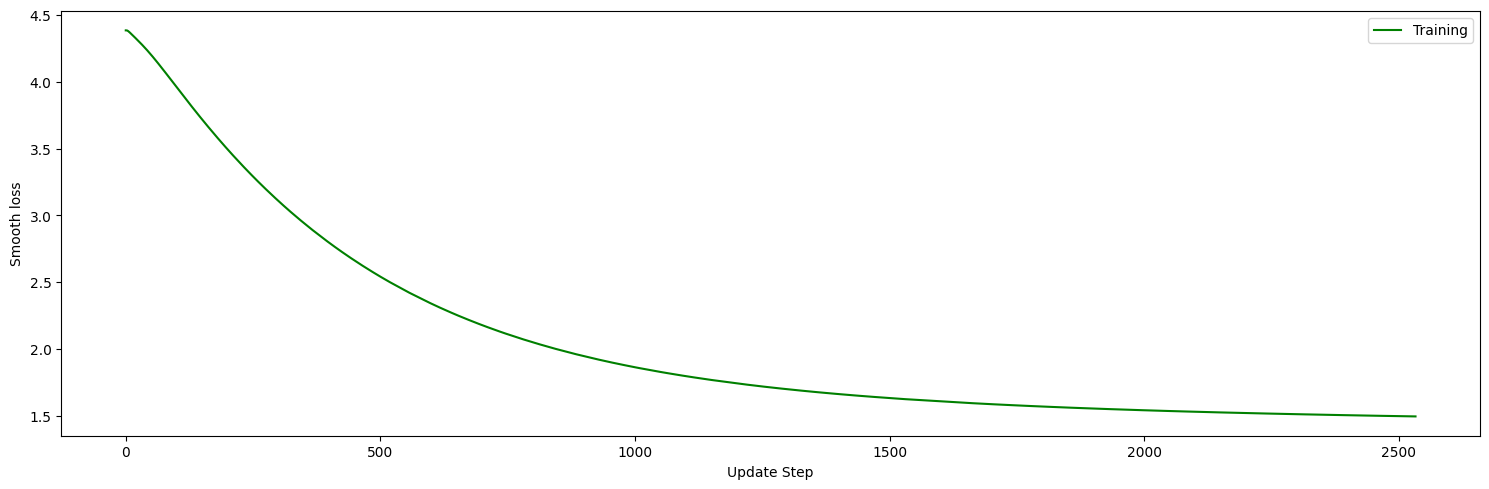

In [14]:
batch_size_test_res = []
for batch_size in [1024]:
    print(f"\n{"="*20} Testing batch size: {batch_size} {"="*20}")
    net = RecurrentNeuralNetwork(data_handler)
    net.add_layer([
        RecurrentLayer(net, K=data_handler.K, m=100, activation="tanh", lam=0),
        FullyConnectedLayer(net, d=100, m=data_handler.K, activation="softmax", lam=0),
    ])
    best_loss = net.train_random_order(25, 0.001, 200, batch_size, best_model_file_name=f"batch_exp_model_{batch_size}_2.npz")
    batch_size_test_res.append((batch_size, best_loss))

In [12]:
best_net = RecurrentNeuralNetwork(data_handler)
best_net.add_layer([
    RecurrentLayer(best_net, K=data_handler.K, m=100, activation="tanh", lam=0),
    FullyConnectedLayer(best_net, d=100, m=data_handler.K, activation="softmax", lam=0),
])
best_net.load_parameters("batch_exp_model_1024_2.npz")

Successfully loaded and set model parameters


In [13]:
''.join(best_net.synthesize(1000))

'icly, lized yaff something without a fately.\n"Winky, don\'t hastered."\n"Harry said the Pootter chatched too laughorly my. . . ."\nSovel her wand to sty ot\nKarkaidde masmss over the told in because said out hon by eath in the Craic Malfoy starridal him closed when him betting it.  Nevilled face.  The read.  Nevill barn with at Harry, then you," Hermione moust, were room.  He in "Just bit no eany asked out, path in Fires, could to would could you\'re was smilved, than they will hannehed. . . .\n"Oug insteeted.  "What Mr. Weasley, and Skull the pub Harry waves, she was had seed.  Obsh had happoner be.  "How yes, as a ske its poss to dead bactling me.  A receroust slipping smabse didn\'t he see of the bellied it, Harry mastred, and yuld.  He will jake wouldn\'t corring thoughther Doblithough," Ron. Halwakin\'s bought eye way.  "Filch impredded seemed axame and into the I sunce real is had said.  "You just see kioly.  There onto hamselt what me picked awave - he had feet his farched fin